In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.path import Path
import utils

/rds/project/rds-rPTGgs6He74/ir-band1/1-4MOST/3-CRS/3-crs_tools/1-4MOST_CRS_tools/CRStools/utils.py:341: SyntaxWarning: invalid escape sequence '\p'
  in radians with limits :math:`[-\pi, \pi]`, :math:`[-\pi/2, \pi/2]`,


## Define RA/Dec box

Set the RA and Dec range in degrees, the projection center, the number of
points to sample along each edge, and the output filename.

In [ ]:
-50 < RA < 50, -70 < dec < -42

In [6]:
# ---- USER PARAMETERS ----
ra_min  = -50.   # degrees
ra_max  = 50.   # degrees
dec_min = -70.   # degrees
dec_max = -42.   # degrees

ra_center  = 110   # projection centre (same as polygon_from_healpix.ipynb)
n_edge_pts = 200   # points per edge (more = smoother curve near the poles)

output_path = 'mask_fp/SPT-3G.npy'
# -------------------------

## Build the rectangular boundary

We walk around the four edges of the box (bottom → right → top → left) so
the vertex order matches the convention used in the healpix-based polygons.

In [7]:
ra_bottom = np.linspace(ra_min, ra_max, n_edge_pts)
ra_top    = np.linspace(ra_max, ra_min, n_edge_pts)
ra_right  = np.full(n_edge_pts, ra_max)
ra_left   = np.full(n_edge_pts, ra_min)

dec_bottom = np.full(n_edge_pts, dec_min)
dec_top    = np.full(n_edge_pts, dec_max)
dec_right  = np.linspace(dec_min, dec_max, n_edge_pts)
dec_left   = np.linspace(dec_max, dec_min, n_edge_pts)

ra_boundary  = np.concatenate([ra_bottom,  ra_right, ra_top,  ra_left])
dec_boundary = np.concatenate([dec_bottom, dec_right, dec_top, dec_left])

# Apply the same projection as polygon_from_healpix.ipynb
ra_proj  = utils.projection_ra(ra_boundary, ra_center=ra_center)   # radians
dec_proj = utils.projection_dec(dec_boundary)                       # radians

poly = Path(np.column_stack([ra_proj, dec_proj]))
print('Polygon vertices:', poly.vertices.shape)

Polygon vertices: (800, 2)


## Quick visual check

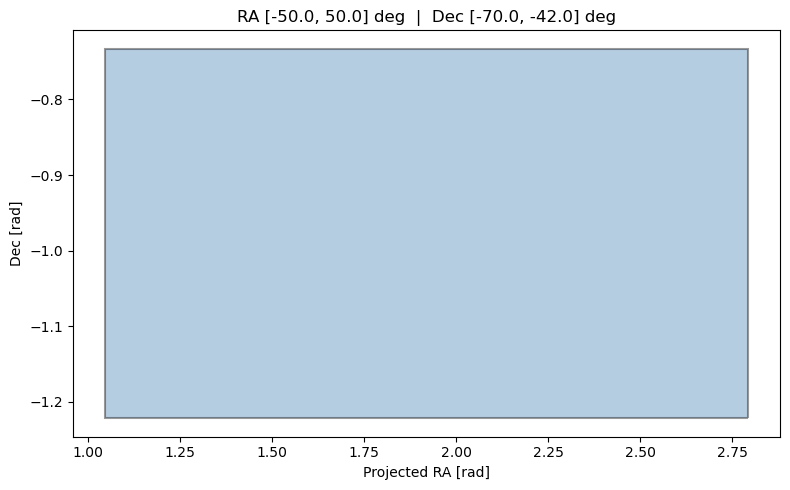

RA  range (projected, rad): 1.0471975511965976 2.792526803190927
Dec range (rad):            -1.2217304763960306 -0.7330382858376184


In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
verts = poly.to_polygons()[0]
patch = patches.PathPatch(poly, facecolor='steelblue', alpha=0.4, edgecolor='k', lw=1.5)
ax.add_patch(patch)
ax.autoscale_view()
ax.set_xlabel('Projected RA [rad]')
ax.set_ylabel('Dec [rad]')
ax.set_title(f'RA [{ra_min}, {ra_max}] deg  |  Dec [{dec_min}, {dec_max}] deg')
plt.tight_layout()
plt.show()

print('RA  range (projected, rad):', verts[:, 0].min(), verts[:, 0].max())
print('Dec range (rad):           ', verts[:, 1].min(), verts[:, 1].max())

## Save — same format as the healpix-based polygons

In [9]:
np.save(output_path, poly.to_polygons()[0])
print(f'Saved to {output_path}  shape={poly.to_polygons()[0].shape}')

Saved to mask_fp/SPT-3G.npy  shape=(800, 2)


## Verify round-trip load

In [10]:
loaded = np.load(output_path)
poly_loaded = Path(loaded)
print('Loaded polygon vertices:', poly_loaded.vertices.shape)
poly_loaded

Loaded polygon vertices: (800, 2)


Path(array([[ 2.7925268 , -1.22173048],
       [ 2.7837563 , -1.22173048],
       [ 2.77498581, -1.22173048],
       ...,
       [ 2.7925268 , -1.216819  ],
       [ 2.7925268 , -1.21927474],
       [ 2.7925268 , -1.22173048]], shape=(800, 2)), None)